# データサイエンス実践A 第13講：if 文と関数
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月20日（金）**

1. 最初に、条件で処理を分ける **if 文**を学ぶ。CES-Alpha の演習「第13講」の `if文基礎001〜004` を解く。
1. 次に、前回の **for 文と if 文を組み合わせて**、条件で色分けしたグラフを描く。`for~if文基礎001`・`002`、`for~if文応用001`〜`003` を解く。
1. そのあと、処理に名前を付ける**関数**（`def`）を「読める」ようになる。CES-Alpha の演習「第13講」の関数の問題を解く。
1. 内包表記・無名関数（lambda）は発展。できる人だけ。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[X. if 文：条件で分ける](#X.-if-文：条件で分ける)**（演習「第13講」）
- [X-1 True と False](#X-1-True-と-False)
- [X-2 if と else](#X-2-if-と-else)
- [X-3 3つ以上に分ける：elif](#X-3-3つ以上に分ける：elif)

**[Y. for と if を組み合わせる](#Y.-for-と-if-を組み合わせる)**
- [Y-0 今日の完成形](#Y-0-今日の完成形)
- [Y-1 くり返しの中で分ける](#Y-1-くり返しの中で分ける)
- [Y-2 条件で色のリストを作る](#Y-2-条件で色のリストを作る)
- [Y-3 色分けした散布図](#Y-3-色分けした散布図)
- [Y-4 色分けした棒グラフ](#Y-4-色分けした棒グラフ)
- [Y-5 世界の国を3色に分ける](#Y-5-世界の国を3色に分ける)

**[AK. 関数](#AK.-関数)**（演習「第13講」）
- [AK-0 関数を使った完成形](#AK-0-関数を使った完成形)
- [AK-1 関数を作る：def と return](#AK-1-関数を作る：def-と-return)
- [AK-2 引数を2つにする](#AK-2-引数を2つにする)
- [AK-3 結果を2つ返す](#AK-3-結果を2つ返す)
- [AK-4 色のリストを返す関数](#AK-4-色のリストを返す関数)

**[AL. 発展：内包表記（できる人だけ）](#AL.-発展：内包表記（できる人だけ）)**（演習「第13講」）
- [AL-1 for でリストを作る処理を1行で](#AL-1-for-でリストを作る処理を1行で)
- [AL-2 計算したリストを作る](#AL-2-計算したリストを作る)
- [AL-3 条件に合うものだけ取り出す](#AL-3-条件に合うものだけ取り出す)
- [AL-4 条件で値を変える](#AL-4-条件で値を変える)

**[AN. 発展：無名関数（できる人だけ）](#AN.-発展：無名関数（できる人だけ）)**（演習「第13講」）
- [AN-1 lambda（無名関数）](#AN-1-lambda（無名関数）)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は **for 文**で、リストの要素を1つずつ取り出して同じ処理をくり返した
- `for k in リスト:` の最後の `:` と、くり返す行の**字下げ（スペース4つ）**を忘れない
- 番号でくり返すときは `for i in range(len(リスト)):`。空のリストに `.append` で値を足していくと、リストが作れる
- for の中で `plt.text(x, y, '文字')` を書いて、散布図の点に国の名前を付けた

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

for s in ['国語', '数学', '英語']:
    print(s)

国語
数学
英語


---
# X. if 文：条件で分ける

**if 文**を使うと、条件によって処理を変えられる。グラフでは、次のようなことができる。
- 条件でグラフの色を変える（X-2：平均点が70点以上なら赤）
- for と組み合わせて、点や棒を1つずつ色分けする（Y-3・Y-4：平均より上か下か、Y-5：一人あたり GDP で3色）
- 目立たせたいものだけ色を変える（Y-5 の「使ってみよう」：日本だけ赤）

## X-1 True と False

- `>`、`<` などで2つの値を比べると、**True**（正しい）か **False**（正しくない）が返ってくる。この2つを**真偽値**という

| 書き方 | 意味 |
|---|---|
| `a == b` | a と b が等しい（`=` を**2つ**。1つだと代入になる） |
| `a != b` | a と b が等しくない |
| `a > b`、`a < b` | より大きい、より小さい |
| `a >= b`、`a <= b` | 以上、以下 |

In [2]:
print(3 > 1)
print(3 < 1)
print(2 == 2)
print('りんご' == 'みかん')

True
False
True
False


▶ **演習**：`if文基礎001`

## X-2 if と else

```python
if 条件:
    条件が True のときの処理
else:
    条件が False のときの処理
```

- for 文と同じく、`:` と**字下げ**が必要
- `else:` の部分は、なくてもよい（そのときは、False なら何もしない）

In [3]:
score = 72

if score >= 60:
    print('合格')
else:
    print('不合格')

合格


- `score = 72` を `score = 45` に変えて、もう一度実行してみよう

▶ **演習**：`if文基礎002`（年齢を変えて、表示が変わることを確かめる）

### if でグラフの色を決める

- if の中で変数に色を入れておけば、条件によってグラフの色が変わる
- 数学の平均点が70点以上なら赤、そうでなければ灰色の棒にする

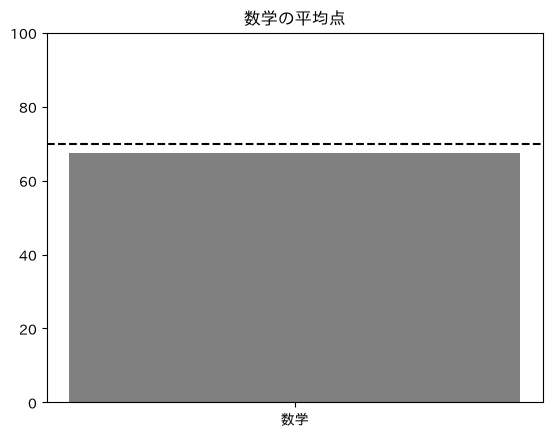

In [4]:
df_exam = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
m = np.mean(df_exam['数学'])

if m >= 70:
    c = 'r'
else:
    c = 'gray'

plt.bar(['数学'], [m], color=c)
plt.axhline(y=70, color='k', linestyle='--')
plt.ylim(0, 100)
plt.title('数学の平均点')
plt.show()

- 数学の平均は 67.4 点なので灰色。`'数学'`（2か所）を `'社会'` に変えると、平均が 75.2 点なので赤になる

▶ **演習**：`if文基礎004`

## X-3 3つ以上に分ける：elif

- `elif 条件:`（else if の略）で、条件をいくつも並べられる。**上から順に**調べ、最初に True になったところだけ実行する

In [5]:
score = 72

if score >= 80:
    print('A')
elif score >= 70:
    print('B')
elif score >= 60:
    print('C')
else:
    print('D')

B


- 72 は「80 以上」ではないので次へ、「70 以上」なので `B` を表示して終わる（`60 以上` も True だが、調べない）
- 条件の順番を変えると結果が変わる。大きい方から順に書く

### 乱数（でたらめな数）
- `if文基礎003` では、ひな形に**乱数**（さいころのように、実行するたびに変わる数）を作る行が入っている
- `rng.integers(0, 10)` で、0 以上 10 未満の整数が1つ出る。何回か実行して、数が変わることを確かめよう

In [6]:
rng = np.random.default_rng()
gacha = rng.integers(0, 10)
print(gacha)

if gacha == 0:
    print('特等')
else:
    print('はずれ')

0
特等


▶ **演習**：`if文基礎003`（`1, 2, 3` を1つの条件で書くには？）

### 2つの値の間かどうか

- 「50 以上 70 以下」のような**間**かどうかは、`elif` を使い、下 → 間 → 上 の順に調べれば書ける

In [7]:
w = 63
low = 50
high = 70

if w < low:
    print('下')
elif w <= high:
    print('間')
else:
    print('上')

間


- `elif w <= high:` まで来たときは、もう `w < low` ではない（low 以上）と分かっている。だから「low 以上 high 以下」を調べたことになる
- `and`（かつ）を使うと1行で書ける。`if low <= w and w <= high:` と `if low <= w <= high:` は同じ意味

In [8]:
if low <= w <= high:
    print('間')
else:
    print('間ではない')

間


---
# Y. for と if を組み合わせる

## Y-0 今日の完成形

30人の数学の点数を棒グラフにし、**60点以上を赤、それ以外を灰色**に色分けしたもの。色のリストを for と if で作っている。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**条件や色を変えて**、グラフがどう変わるかを確かめる
1. そのあと部品（[1]〜[4]）の働きを1つずつ学ぶ（Y-1〜Y-4）

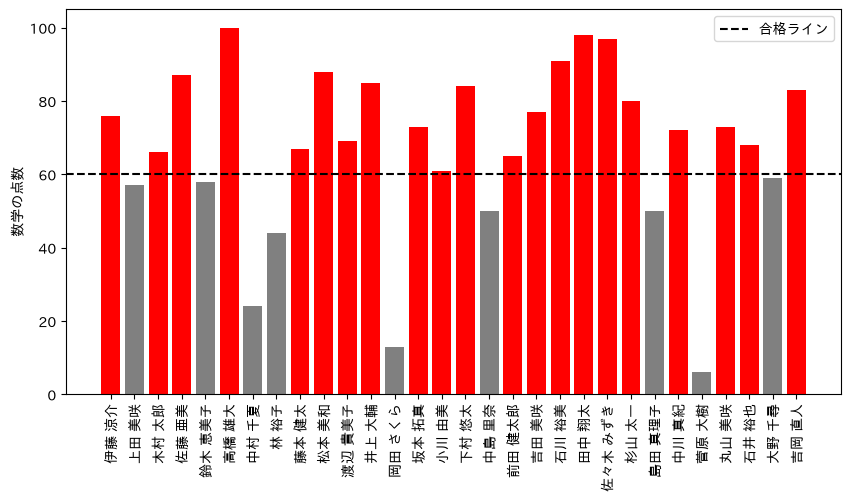

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
math = df['数学']

colors = []  # [1] 空の色リスト
for m in math:  # [2] 1人ずつ取り出す
    if m >= 60:  # [3] 条件で分ける
        colors.append('r')
    else:
        colors.append('gray')

plt.figure(figsize=(10, 5))
plt.bar(df['name'], math, color=colors)  # [4] 色リストを渡す
plt.axhline(y=60, color='k', linestyle='--', label='合格ライン')
plt.xticks(rotation=90)
plt.ylabel('数学の点数')
plt.legend()
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- 条件：`m >= 60` → `m >= np.mean(math)`（平均以上を赤に。補助線も平均にする）
- 色：`'r'` → `'orange'`、`'gray'` → `'lightblue'`
- 補助線を2本（50点と70点）にして、**2本の間だけ**赤にする（X-3「2つの値の間かどうか」の書き方を使う）
- 列：`df['数学']` → `df['英語']`
- `plt.xticks(rotation=90)` は、横軸の名前を90度回して重ならないようにしている。消すとどうなるか

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 空の色リスト | `colors = []` | 第12講 U-5 |
| [2] | 1つずつ取り出す | `for m in math:` | 第12講 U-1 |
| [3] | 条件で分けて追加 | `if m >= 60:` → `colors.append('r')` | Y-1・Y-2 |
| [4] | 色リストを渡す | `plt.bar(x, y, color=colors)` | Y-4 |

In [10]:
# 上のコードを貼り付けて、値を変えてみよう

## Y-1 くり返しの中で分ける

- for の中に if を書く。**if の中はさらに字下げ**する（スペース8つ）

In [11]:
for k in range(10):
    if k >= 6:
        print(k, '6以上')
    else:
        print(k, '6未満')

0 6未満
1 6未満
2 6未満
3 6未満
4 6未満
5 6未満
6 6以上
7 6以上
8 6以上
9 6以上


## Y-2 条件で色のリストを作る

- 第４講では、点ごとの色のリストを**手で**書いた。for と if を使えば、データから**自動で**作れる
- 空のリスト → for で1つずつ取り出す → if で分けて `.append` する

In [12]:
mylist = []
for k in range(10):
    if k >= 6:
        mylist.append('m')
    else:
        mylist.append('c')
print(mylist)

['c', 'c', 'c', 'c', 'c', 'c', 'm', 'm', 'm', 'm']


▶ **演習**：`for~if文基礎001`

▶ **演習**：`for~if文基礎002`（ひな形で乱数を20個作っている。`rng.integers(0, 10, 20)` の `20` が個数）

## Y-3 色分けした散布図

- 作った色のリストを、散布図の `c=` に渡す（第４講）
- `rng.normal(65, 15, 20)` は、平均 65・標準偏差 15 の、正規分布（テストの点数のような山形の分布）に従う乱数を20個作る。`default_rng(348309421)` のように数を入れると、**毎回同じ乱数**が出る

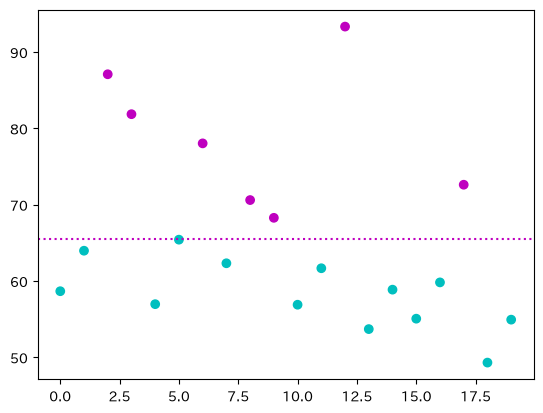

In [13]:
rng = np.random.default_rng(348309421)
data = rng.normal(65, 15, 20)
mean = np.mean(data)

p = []
for k in data:
    if k > mean:
        p.append('m')
    else:
        p.append('c')

plt.scatter(range(len(data)), data, c=p)
plt.axhline(y=mean, color='m', linestyle=':')
plt.show()

▶ **演習**：`for~if文応用001`（ひな形の `data.mean()` は `np.mean(data)` と同じ意味）

## Y-4 色分けした棒グラフ

- 棒グラフでは `color=` に色のリストを渡す（散布図の `c=` と違うので注意）

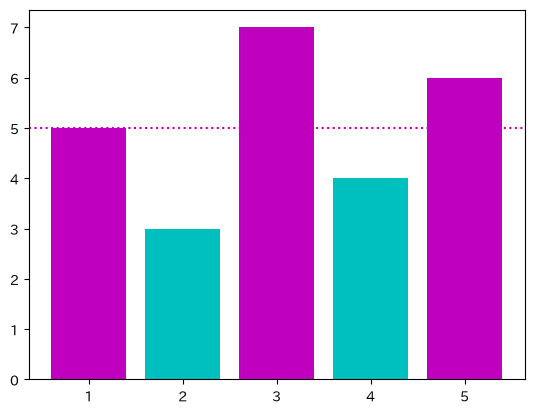

In [14]:
x = [1, 2, 3, 4, 5]
y = [5, 3, 7, 4, 6]
mean = np.mean(y)

mycolor = []
for k in y:
    if k >= mean:
        mycolor.append('m')
    else:
        mycolor.append('c')

plt.bar(x, y, color=mycolor)
plt.axhline(y=mean, color='m', linestyle=':')
plt.show()

▶ **演習**：`for~if文応用002`（ひな形の `np.array([…])` はリストと同じように使ってよい）

## Y-5 世界の国を3色に分ける

- 第12講 U-7 の世界30か国の散布図を、一人あたり GDP で3色に分ける
- 3万ドル以上は赤、5千ドル以上はオレンジ、それより少ないと青。**elif**（X-3）で3つに分ける

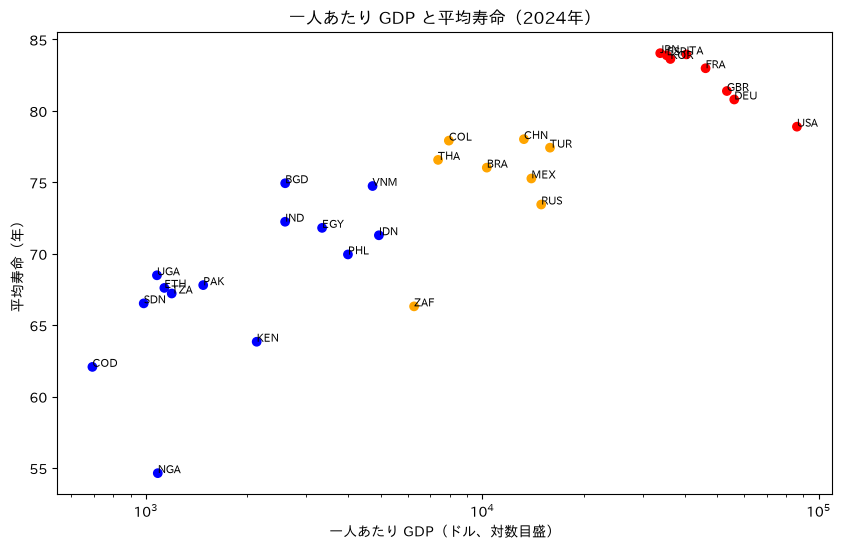

In [15]:
df_wb = pd.read_excel('dsa2026data.xlsx', sheet_name='worldbank')
gdp = df_wb['一人あたりGDP']
life = df_wb['出生時平均寿命']
country = df_wb['country']

colors = []
for g in gdp:
    if g >= 30000:
        colors.append('r')
    elif g >= 5000:
        colors.append('orange')
    else:
        colors.append('b')

plt.figure(figsize=(10, 6))
plt.scatter(gdp, life, c=colors)
for i in range(len(df_wb)):
    plt.text(gdp[i], life[i], country[i], fontsize=8)
plt.xscale('log')
plt.title('一人あたり GDP と平均寿命（2024年）')
plt.xlabel('一人あたり GDP（ドル、対数目盛）')
plt.ylabel('平均寿命（年）')
plt.show()

- 赤（豊かな国）は平均寿命も長く、右上にまとまっている
- 国の名前を書く for（第12講 U-7）と、色を決める for を、別々に書いている

▶ **演習**：`for~if文応用003`

### 使ってみよう
- Y-5 の散布図で、日本（`'JPN'`）だけ赤、ほかは灰色にしてみよう（`country[i] == 'JPN'` で調べる）

In [16]:
# ここで試してみよう

---
# AK. 関数

## AK-0 関数を使った完成形

5教科の平均点の棒グラフ。**70点以上の教科だけ色を変える**処理（Y-4 と同じ for と if）を、関数 `get_color` にまとめている。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**境目の点数や色を変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[2]）の働きを1つずつ学ぶ（AK-1〜AK-4）

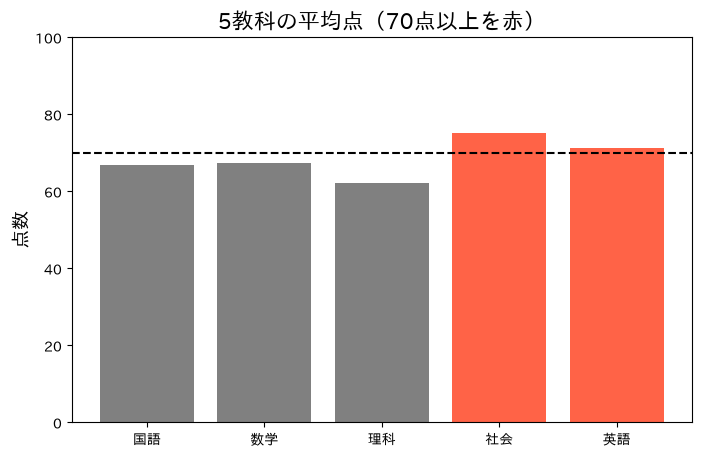

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

def get_color(values, border):  # [1] 関数を作る
    colors = []
    for v in values:
        if v >= border:
            colors.append('tomato')
        else:
            colors.append('gray')
    return colors

df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
subjects = ['国語', '数学', '理科', '社会', '英語']
means = []
for s in subjects:
    means.append(np.mean(df[s]))

plt.figure(figsize=(8, 5))
plt.bar(subjects, means, color=get_color(means, 70))  # [2] 関数を使う
plt.axhline(y=70, color='k', linestyle='--')
plt.ylim(0, 100)
plt.title('5教科の平均点（70点以上を赤）', fontsize=16)
plt.ylabel('点数', fontsize=14)
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- `get_color(means, 70)` → `get_color(means, 65)`（境目を変える。`axhline` の `y=70` もそろえる）
- `'tomato'` → `'orange'`、`'gray'` → `'lightgray'`

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 関数を作る | `def 名前(引数):` → `return 結果` | AK-1〜AK-4 |
| [2] | 関数を使う | `名前(値)` | AK-1 |

In [18]:
# 上のコードを貼り付けて、値を変えてみよう

## AK-1 関数を作る：def と return

- 関数は「材料（**引数**）を入れると、結果を返してくれる箱」。`print()`、`len()`、`np.mean()` も関数
- `def 名前(引数):` で自分の関数を作る。下の行は**字下げ**して書き、`return` で結果を返す（for・if と同じく `:` と字下げ）
- 作っただけでは何も起きない。`名前(値)` と書いて**使う（呼び出す）**と、はじめて動く

In [19]:
def tax_in(price):
    return round(price * 1.1)

print(tax_in(100))
print(tax_in(250))

110
275


- `tax_in(100)` と書くと、`price` に 100 が入って `round(100 * 1.1)` が計算され、110 が返ってくる
- `round()` は四捨五入（小数点以下を丸める）

▶ **演習**：`関数01`（入力した値の3倍を返す）

## AK-2 引数を2つにする

- 引数は `,` で区切っていくつでも書ける。呼び出すときも同じ順番で値を入れる

In [20]:
def rect_area(a, b):
    return a * b

print(rect_area(3, 5))
print(rect_area(10, 2))

15
20


- `x ** n` は「x の n 乗」（例：`2 ** 3` は 8）

▶ **演習**：`関数02`（x の n 乗を返す）

## AK-3 結果を2つ返す

- `return` の後に `,` で区切って書くと、結果を2つ返せる。受け取るときは `変数1, 変数2 = 関数(…)`

In [21]:
def min_max(values):
    return min(values), max(values)

print(min_max([62, 75, 58, 81, 70]))

low, high = min_max([62, 75, 58, 81, 70])
print('最低点', low)
print('最高点', high)

(58, 81)
最低点 58
最高点 81


- そのまま `print` すると `(58, 81)` と丸かっこでまとめて表示される
- 2つの変数で受け取ると、`low` に 58、`high` に 81 が入る

▶ **演習**：`関数03`（和と差を返す）、`関数04`（2つの変数で受け取る）

## AK-4 色のリストを返す関数

- Y-2 の「for と if で色のリストを作る」処理を、関数にまとめる。データと境目を変えても、同じ関数を使い回せる
- 関数の中の for・if は、さらに字下げする（スペース4つずつ）

['gray', 'tomato', 'gray', 'tomato', 'tomato', 'gray', 'tomato', 'gray', 'tomato', 'gray']


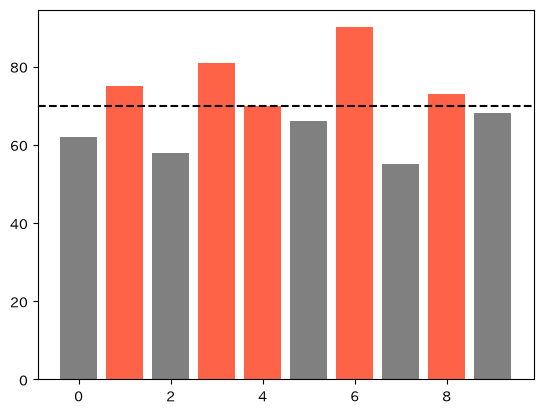

In [22]:
def get_mycolor(values, border):
    mycolor = []
    for v in values:
        if v >= border:
            mycolor.append('tomato')
        else:
            mycolor.append('gray')
    return mycolor

scores = [62, 75, 58, 81, 70, 66, 90, 55, 73, 68]
print(get_mycolor(scores, 70))

plt.bar(range(len(scores)), scores, color=get_mycolor(scores, 70))
plt.axhline(y=70, color='k', linestyle='--')
plt.show()

- `return` は for の外（`for` と同じ字下げ）に書く。for の中に書くと、1回目で関数が終わってしまう
- 「上限と下限の間」は `if lim1 < v < lim2:` と書ける

- 関数05 のひな形の `rng.integers(0, 10, 20)` は、0以上10未満の整数を20個、乱数で作る（X-3）。実行するたびに変わる

▶ **演習**：`関数05`（上限と下限の間だけ色を変える）

---
# AL. 発展：内包表記（できる人だけ）

ここは授業の本編ではない。ネットや AI のコードに出てきたときに読めるように、紹介しておく。

## AL-1 for でリストを作る処理を1行で

- **内包表記**：for でリストを作る処理を、`[ ]` の中に1行で書いたもの。下の2つは同じ結果

In [23]:
prices = [100, 250, 400]

result = []
for p in prices:
    result.append(tax_in(p))
print(result)

print([tax_in(p) for p in prices])

[110, 275, 440]
[110, 275, 440]


- 読み方：`[tax_in(p) for p in prices]` は「prices から p を1つずつ取り出し、`tax_in(p)` を計算して並べたリスト」
- **後ろから読む**とわかりやすい：`for p in prices`（取り出し方）→ 前の `tax_in(p)`（何を並べるか）
- `range(-10, 10)` の中身をリストで見るには、`list(range(-10, 10))` でもよい

In [24]:
print([k for k in range(-10, 10)])
print(list(range(-10, 10)))

[-10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[-10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


▶ **演習**：`内包表記01`（range(-10, 10) をリストにする。内包表記と list() の2通り）

## AL-2 計算したリストを作る

- 前の部分に計算を書くと、計算した結果のリストになる
- np.array にすれば、内包表記を使わなくても全部に同じ計算ができる（第９講 AB-2）

In [25]:
print([k * 2 for k in range(5)])
print(np.array(range(5)) * 2)

[0, 2, 4, 6, 8]
[0 2 4 6 8]


▶ **演習**：`内包表記02`（2乗する。内包表記と np.array の2通り）

## AL-3 条件に合うものだけ取り出す

- 後ろに `if 条件` を付けると、条件に合うものだけが残る
- `%` は割り算の**余り**。`k % 2 == 0` は「2で割り切れる」＝偶数、`k % 2 == 1` は奇数

In [26]:
scores = [62, 75, 58, 81, 70, 66, 90, 55, 73, 68]
print([s for s in scores if s >= 70])

print([k for k in range(10) if k % 2 == 0])

[75, 81, 70, 90, 73]
[0, 2, 4, 6, 8]


▶ **演習**：`内包表記03`（奇数だけ取り出す）

## AL-4 条件で値を変える

- 前の部分に `A if 条件 else B` を書くと、条件に合えば A、合わなければ B を並べる
- **AL-3 との違い**：AL-3 は `if` が後ろ（取り出す）。AL-4 は `if … else` が前（すべて残して、値を変える）
- AK-4 の `get_mycolor` の中身（for・if・else の7行）は、これで1行になる（`return ['tomato' if v >= border else 'gray' for v in values]`）
- 作った色のリストは、そのまま `color=` に入れられる。下のグラフは AK-4 の `get_mycolor` を使ったグラフと同じになる

['gray', 'tomato', 'gray', 'tomato', 'tomato', 'gray', 'tomato', 'gray', 'tomato', 'gray']


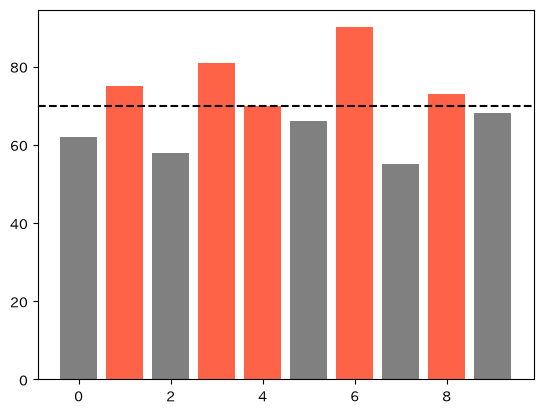

[3 5 1 4 3 3 5 6 1 1]


['小', '大', '小', '大', '小', '小', '大', '大', '小', '小']


In [27]:
scores = [62, 75, 58, 81, 70, 66, 90, 55, 73, 68]
print(['tomato' if s >= 70 else 'gray' for s in scores])

plt.bar(range(len(scores)), scores, color=['tomato' if s >= 70 else 'gray' for s in scores])
plt.axhline(y=70, color='k', linestyle='--')
plt.show()

rng = np.random.default_rng()
dice = rng.integers(1, 7, 10)
print(dice)
print(['大' if d >= 4 else '小' for d in dice])

- `rng.integers(1, 7, 10)` は、1以上7未満の整数を10個（サイコロを10回振る）。実行するたびに変わる

▶ **演習**：`内包表記04`（偶数は2倍、奇数は 'odd'）、`内包表記05`（サイコロの目で色を変える）

---
# AN. 発展：無名関数（できる人だけ）

## AN-1 lambda（無名関数）

- `lambda 引数: 結果` は、名前を付けない小さな関数。`def` を1行で書いたもの。下の2つは同じ

In [28]:
def tax_in(price):
    return round(price * 1.1)

tax_in2 = lambda price: round(price * 1.1)

print(tax_in(100))
print(tax_in2(100))

110
110


- `lambda 引数: 結果` の部分は、それ自体が関数（**関数オブジェクト**）になる。名前を付けずに、`( )` で囲んだ後ろに `(値)` を付けると、その場で呼び出せる
- 下の `(lambda x, y: x + y)(1, 2)` は、`x` に 1、`y` に 2 が入って 3 が返ってくる
- 数学の **`y = f(x)`**（関数 f に x を入れると、結果 y が返ってくる）と、形がよく対応している

| 数学 | Python（`sum_result = (lambda x, y: x + y)(1, 2)`） |
|---|---|
| `f`（関数） | `(lambda x, y: x + y)`（関数そのもの） |
| `x`（入れる値） | `(1, 2)` |
| `y`（返ってくる結果） | `sum_result` |

- `f = lambda x, y: x + y` と名前を付けたときの `sum_result = f(1, 2)` の `f` を、`( )` で囲んだ lambda そのものに置き換えた形
- 注意：lambda の中の `y` は引数の名前で、`y = f(x)` の `y` とは別のもの

In [29]:
print((lambda x, y: x + y)(1, 2))

sum_result = (lambda x, y: x + y)(1, 2)
print(sum_result)

3
3


- 引数が2つなら `lambda a, b: a * b`。結果を2つ返すなら `lambda a, b: (a + b, a - b)`
- pandas の `apply` と組み合わせると、列の全部の値に同じ処理ができる

In [30]:
df_exam = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
print(df_exam['数学'].apply(lambda m: '合格' if m >= 60 else '不合格').head())

0     合格
1    不合格
2     合格
3     合格
4    不合格
Name: 数学, dtype: str


▶ **演習**：`無名関数01`（引数1つ）、`無名関数02`（引数2つ）、`無名関数03`（2つ返す）、`無名関数04`（名前を付けずにその場で呼び出す）

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| **以下は if 文** | |
| 比べる | `==`（等しい）、`!=`、`>`、`<`、`>=`、`<=` |
| 条件で分ける | `if 条件:` → `else:`（`:` と字下げ） |
| 3つ以上に分ける | `if` → `elif 条件:` → `else:`（上から順に調べる） |
| 2つの値の間 | `if low <= w <= high:` |
| **以下は for と if** | |
| 条件で色のリストを作る | `colors = []` → `for k in データ:` → `if k >= 60:` → `colors.append('r')` |
| 散布図・棒グラフに渡す | 散布図は `c=colors`、棒グラフは `color=colors` |
| **以下は関数** | |
| 関数を作る | `def 名前(引数):` → 字下げして `return 結果` |
| 関数を使う | `名前(値)` |
| 2つ返す・受け取る | `return a, b` → `x, y = 名前(…)` |
| **以下は発展** | |
| 内包表記 | `[式 for v in リスト]`、`[v for v in リスト if 条件]`、`[A if 条件 else B for v in リスト]` |
| 無名関数 | `lambda 引数: 結果` |

- 関数は**読めればよい**。自分で書くときは、for・if だけで書いてもまったく問題ない

次回（第14講）は**実データを Excel で整えて読む**ことと、**回帰**（散布図にいちばん合う直線を引く）。